In [10]:
# Import the geopandas and geoplot libraries
import pandas as pds
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import plotly.express as px
import json

In [11]:
import plotly.io as pio
pio.renderers.default = "notebook"

In [12]:
df = pds.read_csv("../data/Life_Expectancy_at_Birth.csv")
df_europe = df[df["Continent"] == "Europe"].copy()

In [13]:
gdf = gpd.read_file("../data/CNTR_RG_20M_2024_3035.geojson")
gdf = gdf.to_crs(epsg=4326)
europe_countries = json.loads(gdf.to_json())

In [14]:
europe_countries['features'][0]['properties']

{'CNTR_ID': 'CD',
 'CNTR_NAME': 'République Démocratique du Congo-Kongo-Kongó-Kongu-Kongo',
 'NAME_ENGL': 'Democratic Republic of The Congo',
 'NAME_FREN': 'République démocratique du Congo',
 'ISO3_CODE': 'COD',
 'SVRG_UN': 'UN Member State',
 'CAPT': 'Kinshasa',
 'EU_STAT': 'F',
 'EFTA_STAT': 'F',
 'CC_STAT': 'F',
 'NAME_GERM': 'Demokratische Republik Kongo'}

In [15]:
country_id_map = {}
for feature in europe_countries['features']:
    feature['id'] = feature['properties']['CNTR_ID']
    country_id_map[feature['properties']['NAME_ENGL']] = feature['id']

In [16]:
df_europe['id'] = df_europe['Country'].map(country_id_map)

In [20]:
df_europe['Life Expectancy at Birth (2021)'] = (
    df_europe['Life Expectancy at Birth (2021)'] - 
    df_europe['Life Expectancy at Birth (2021)'].mean())
max_abs = abs(df_europe['Life Expectancy at Birth (2021)']).max()
# Task 1: Maps and Colormaps
fig = px.choropleth(df_europe, locations = 'id',
                    geojson = europe_countries,
                    color = 'Life Expectancy at Birth (2021)',
                    color_continuous_scale='RdBu',
                    color_continuous_midpoint=0,
                    range_color=[-max_abs, max_abs],
                    scope = 'europe')
fig.update_geos(fitbounds = 'locations', visible = False)
fig.show()

In [205]:
# Task 2: Heatmaps and ClusterMaps
import seaborn as sns

df_europe_2009_2021 = df_europe[["Country",'Life Expectancy at Birth (2005)', 'Life Expectancy at Birth (2006)',
       'Life Expectancy at Birth (2007)', 'Life Expectancy at Birth (2008)',
       'Life Expectancy at Birth (2009)', 'Life Expectancy at Birth (2010)',
       'Life Expectancy at Birth (2011)', 'Life Expectancy at Birth (2012)',
       'Life Expectancy at Birth (2013)', 'Life Expectancy at Birth (2014)',
       'Life Expectancy at Birth (2015)', 'Life Expectancy at Birth (2016)',
       'Life Expectancy at Birth (2017)', 'Life Expectancy at Birth (2018)',
       'Life Expectancy at Birth (2019)', 'Life Expectancy at Birth (2020)',
       'Life Expectancy at Birth (2021)']]
df_europe_2009_2021 = df_europe_2009_2021.set_index('Country')
df_europe_2009_2021.columns = df_europe_2009_2021.columns.str.extract(r'\((\d+)\)')[0]
df_europe_2009_2021


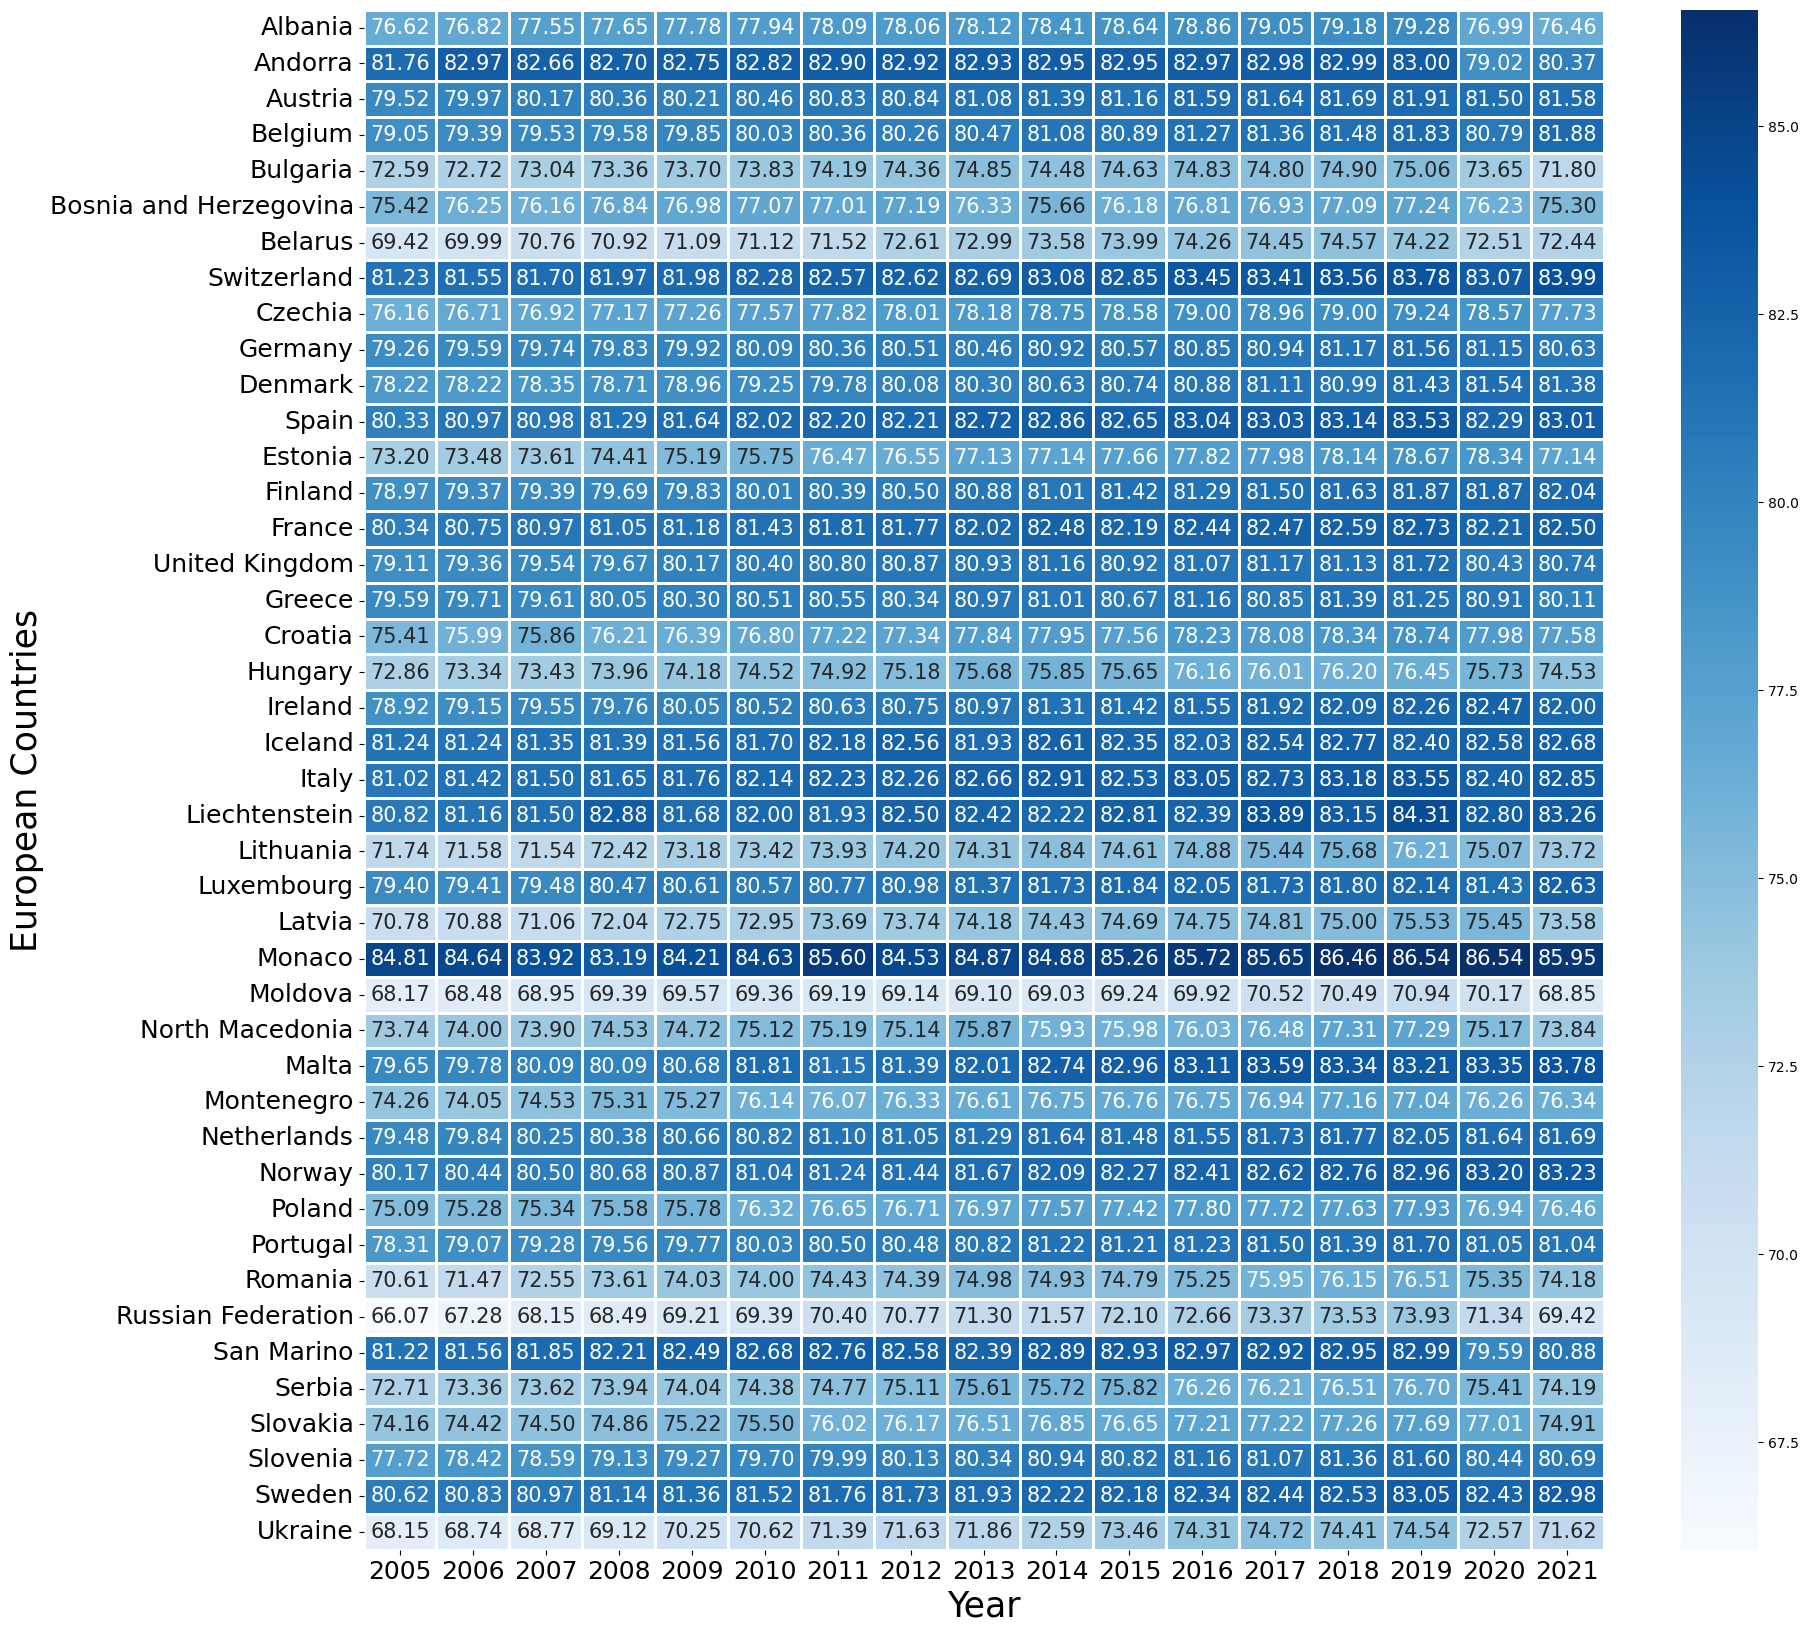

In [206]:
# Heatmap
plt.figure(figsize=(20,20))
ax = sns.heatmap(df_europe_2009_2021, cmap = 'Blues', fmt = '.2f',
                annot = True, annot_kws = {'size': 15}, 
                cbar = True, linewidths = 1, linecolor = 'white')

ax.tick_params(axis='x', labelsize=18) 
ax.tick_params(axis='y', labelsize=18)  # y-axis tick labels (countries)
ax.set_xlabel('Year', fontsize = 25)
ax.set_ylabel('European Countries', fontsize = 25)
plt.show()

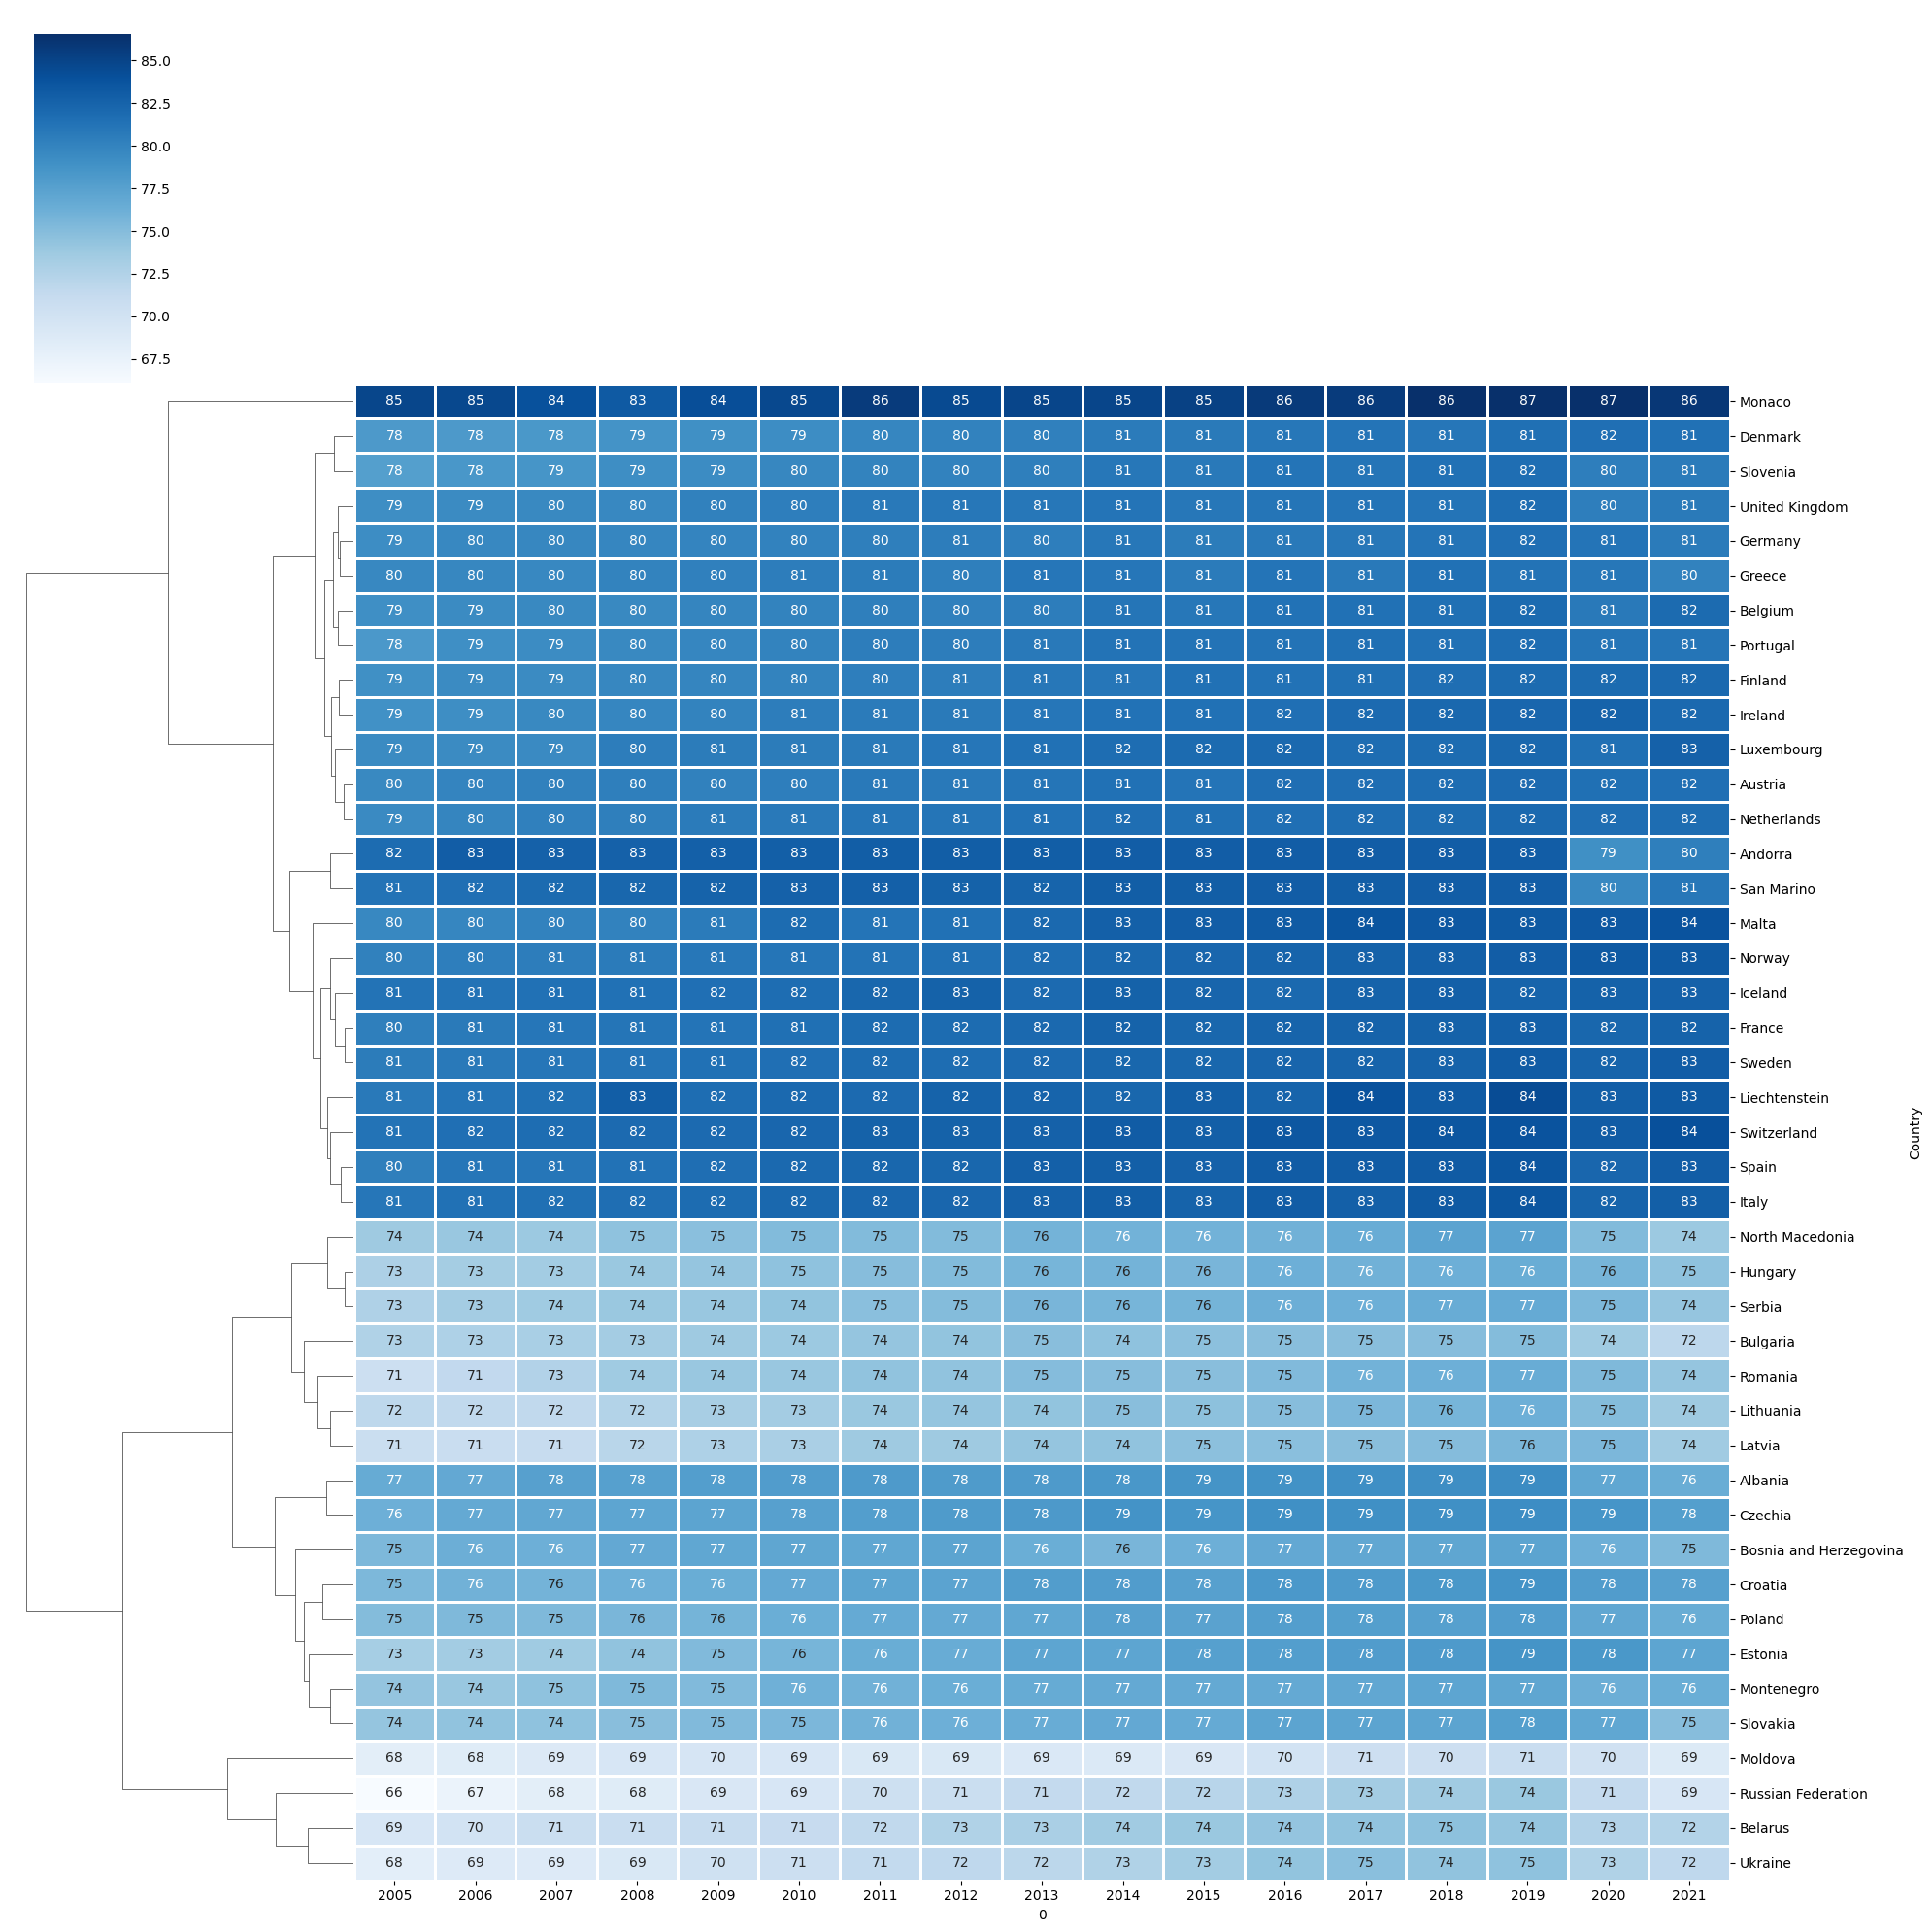

In [231]:
# Clustermap
bx = sns.clustermap(df_europe_2009_2021, cmap = 'Blues', annot = True,
                    cbar = True, linewidths = 1, linecolor = 'white',
                    col_cluster=False, figsize=(20,20))
bx.tick_params(axis='x', labelsize=10) 
bx.tick_params(axis='y', labelsize=10)  # y-axis tick labels (countries)
bx.savefig("my_clustermap.png", dpi=300, bbox_inches='tight')
plt.show()
